# Classificação - Diagnóstico de Diabetes

## 1. Definição do problema

O diabetes é uma doença crônica que afeta milhões de pessoas e, quando não é diagnosticada cedo, pode causar complicações graves como problemas nos rins, na visão e no coração. Um modelo que indique quais pacientes têm maior chance de ter diabetes pode ajudar a priorizar exames e acompanhamento médico.

**Pergunta principal:** É possível prever se uma paciente tem diabetes a partir de medidas clínicas simples?

**Tipo de problema:** Classificação, pois a variável alvo tem duas categorias (tem diabetes ou não tem).

## 2. Apresentação da base de dados

- **Nome:** Pima Indians Diabetes Database
- **Origem:** National Institute of Diabetes and Digestive and Kidney Diseases (EUA). Disponível no OpenML: https://www.openml.org/d/37
- **Registros:** 768 pacientes, todas mulheres com pelo menos 21 anos, de origem indígena Pima.
- **Colunas:** 9 (8 variáveis de entrada e 1 variável alvo)

| Coluna original | Nome usado | Significado |
|---|---|---|
| preg | gestacoes | número de vezes que esteve grávida |
| plas | glicose | concentração de glicose no sangue (teste de tolerância à glicose) |
| pres | pressao | pressão arterial diastólica (mm Hg) |
| skin | pele | espessura da dobra cutânea do tríceps (mm) |
| insu | insulina | insulina no sangue após 2 horas (mu U/ml) |
| mass | imc | índice de massa corporal |
| pedi | historico_familiar | função que indica histórico de diabetes na família |
| age | idade | idade em anos |
| class | diabetes | **variável alvo**: tested_positive (tem diabetes) ou tested_negative (não tem) |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# carregando os dados
df = pd.read_csv('../dados/diabetes.csv')

# renomeando as colunas para facilitar a leitura
df = df.rename(columns={
    'preg': 'gestacoes',
    'plas': 'glicose',
    'pres': 'pressao',
    'skin': 'pele',
    'insu': 'insulina',
    'mass': 'imc',
    'pedi': 'historico_familiar',
    'age': 'idade',
    'class': 'diabetes'
})

print('Linhas:', df.shape[0])
print('Colunas:', df.shape[1])

Linhas: 768
Colunas: 9


## 3. Análise exploratória dos dados

In [3]:
# primeiras linhas
df.head()

,gestacoes,glicose,pressao,pele,insulina,imc,historico_familiar,idade,diabetes
0,6,148,72,35,0,33.6,0.627,50,tested_positive
1,1,85,66,29,0,26.6,0.351,31,tested_negative
2,8,183,64,0,0,23.3,0.672,32,tested_positive
3,1,89,66,23,94,28.1,0.167,21,tested_negative
4,0,137,40,35,168,43.1,2.288,33,tested_positive


In [4]:
# tipos de dados
df.dtypes

gestacoes               int64
glicose                 int64
pressao                 int64
pele                    int64
insulina                int64
imc                   float64
historico_familiar    float64
idade                   int64
diabetes                  str
dtype: object

In [5]:
# valores ausentes
df.isnull().sum()

gestacoes             0
glicose               0
pressao               0
pele                  0
insulina              0
imc                   0
historico_familiar    0
idade                 0
diabetes              0
dtype: int64

In [6]:
# registros duplicados
print('Duplicados:', df.duplicated().sum())

Duplicados: 0


In [7]:
# estatisticas basicas
df.describe().round(2)

,gestacoes,glicose,pressao,pele,insulina,imc,historico_familiar,idade
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00


Pelo `describe` dá para ver que algumas colunas têm valor mínimo igual a 0, o que não faz sentido para glicose, pressão, pele, insulina e IMC (ninguém tem pressão ou IMC zero). Isso indica que o 0 foi usado no lugar de valores não medidos.

In [8]:
# quantidade de zeros nas colunas onde zero nao faz sentido
colunas_zero = ['glicose', 'pressao', 'pele', 'insulina', 'imc']
(df[colunas_zero] == 0).sum()

glicose       5
pressao      35
pele        227
insulina    374
imc          11
dtype: int64

diabetes
tested_negative    500
tested_positive    268
Name: count, dtype: int64


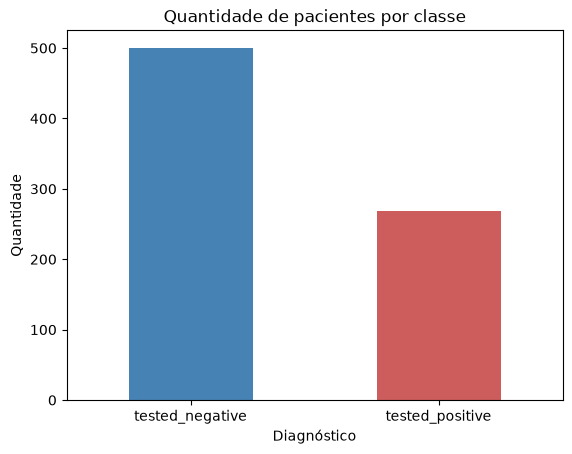

In [9]:
# distribuicao da variavel alvo
print(df['diabetes'].value_counts())

df['diabetes'].value_counts().plot(kind='bar', color=['steelblue', 'indianred'])
plt.title('Quantidade de pacientes por classe')
plt.xlabel('Diagnóstico')
plt.ylabel('Quantidade')
plt.xticks(rotation=0)
plt.show()

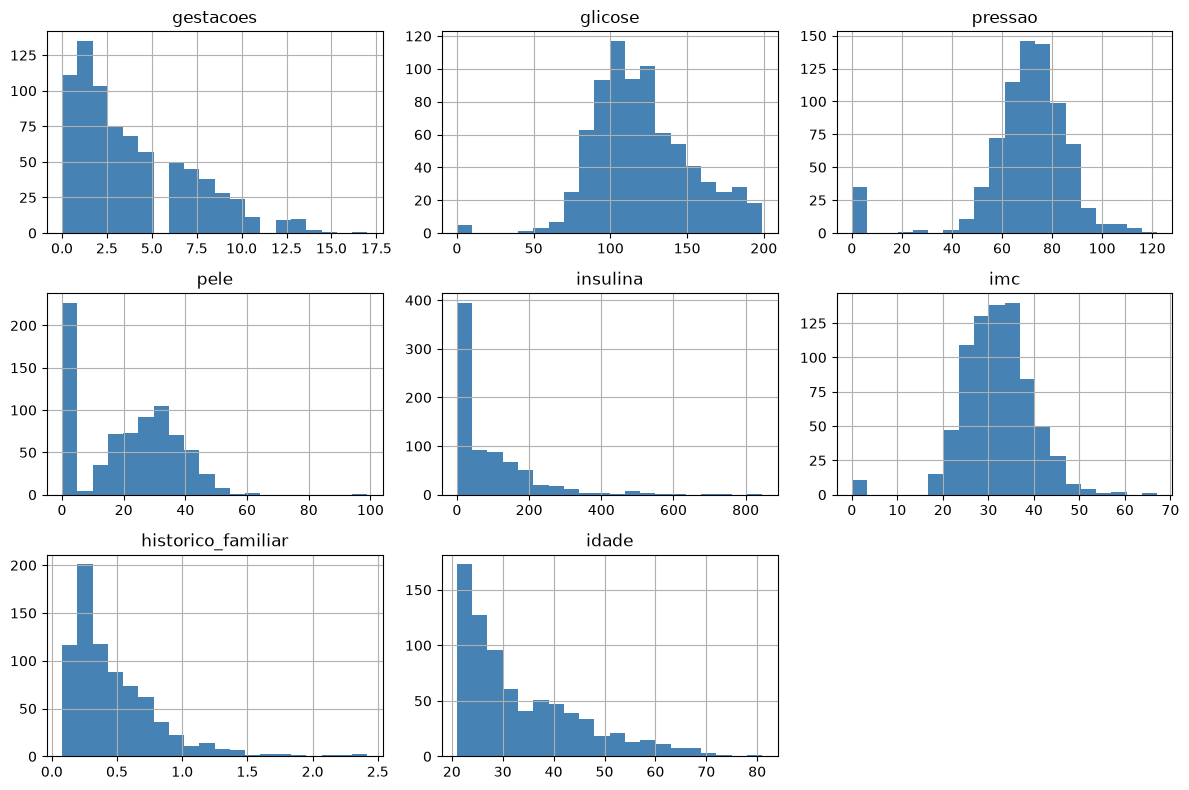

In [10]:
# histogramas das variaveis numericas
df.hist(figsize=(12, 8), bins=20, color='steelblue')
plt.tight_layout()
plt.show()

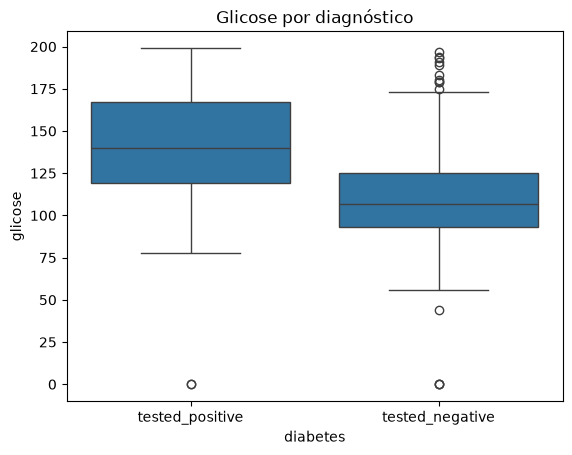

In [11]:
# boxplot da glicose por diagnostico
sns.boxplot(data=df, x='diabetes', y='glicose')
plt.title('Glicose por diagnóstico')
plt.show()

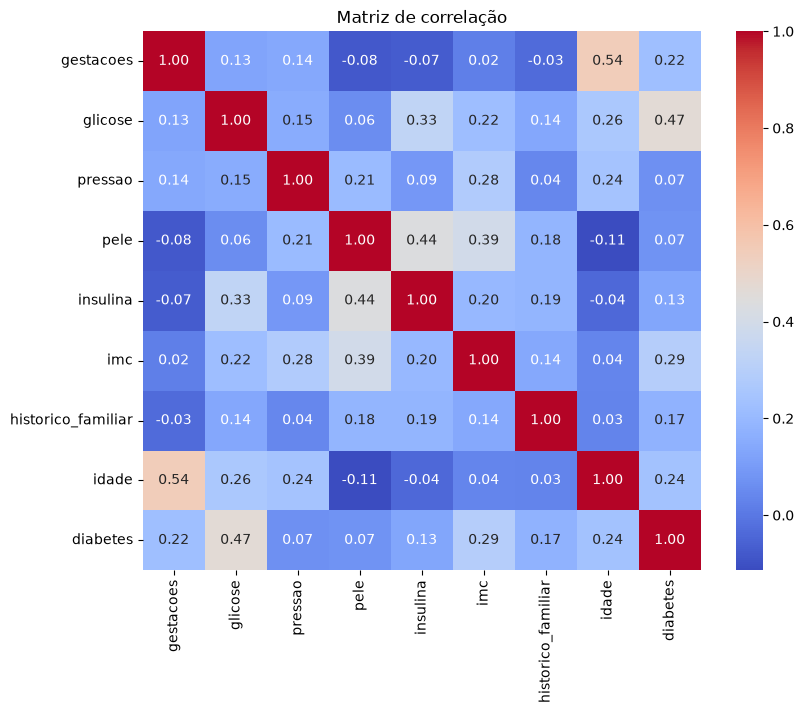

In [12]:
# matriz de correlacao
df_corr = df.copy()
df_corr['diabetes'] = (df_corr['diabetes'] == 'tested_positive').astype(int)

plt.figure(figsize=(9, 7))
sns.heatmap(df_corr.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matriz de correlação')
plt.show()

**O que a análise mostrou:**

- A base tem 768 registros, nenhum valor ausente declarado e nenhum duplicado.
- Porém existem zeros que na verdade são valores não medidos: 374 na insulina (quase metade), 227 na pele, 35 na pressão, 11 no IMC e 5 na glicose. Isso será tratado na preparação.
- As classes estão desbalanceadas: 500 pacientes sem diabetes (65%) e 268 com diabetes (35%).
- A **glicose** é a variável mais relacionada ao diagnóstico (correlação de 0,47). No boxplot, a mediana da glicose de quem tem diabetes (140) é bem maior que a de quem não tem (107).
- Depois da glicose, as variáveis mais relacionadas são IMC (0,29), idade (0,24) e número de gestações (0,22).

## 4. Preparação dos dados

Decisões tomadas:

1. **Duplicados:** a base não tem registros duplicados, então nada foi removido.
2. **Zeros como valores ausentes:** os zeros de glicose, pressão, pele, insulina e IMC foram trocados por valor ausente (NaN) e depois preenchidos com a **mediana** da coluna. A mediana foi escolhida no lugar da média porque é menos afetada por valores extremos (a insulina, por exemplo, tem valores muito altos). Não foi possível apenas remover essas linhas porque quase metade das pacientes não tem insulina medida.
3. **Variável alvo:** transformada em número (1 = tem diabetes, 0 = não tem).
4. **Treino e teste:** 80% para treino e 20% para teste, usando `stratify` para manter a mesma proporção de classes nos dois conjuntos.
5. **Medianas calculadas só no treino:** para o modelo não "ver" nenhuma informação dos dados de teste antes da avaliação.
6. **Padronização:** as colunas estão em escalas muito diferentes (idade vai até 81, insulina até 846). Modelos como KNN, SVM e Regressão Logística são sensíveis a isso, então os dados foram padronizados com `StandardScaler` (média 0 e desvio padrão 1).

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# trocando os zeros por valor ausente
df[colunas_zero] = df[colunas_zero].replace(0, np.nan)

# transformando a variavel alvo em 0 e 1
df['diabetes'] = (df['diabetes'] == 'tested_positive').astype(int)

# separando entradas (X) e alvo (y)
X = df.drop(columns='diabetes')
y = df['diabetes']

# dividindo em treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# preenchendo os ausentes com a mediana do treino
medianas = X_treino.median()
X_treino = X_treino.fillna(medianas)
X_teste = X_teste.fillna(medianas)

print('Ausentes no treino:', X_treino.isnull().sum().sum())
print('Ausentes no teste:', X_teste.isnull().sum().sum())

Ausentes no treino: 0
Ausentes no teste: 0


In [14]:
# padronizando os dados
scaler = StandardScaler()
X_treino_pad = scaler.fit_transform(X_treino)
X_teste_pad = scaler.transform(X_teste)

print('Treino:', X_treino_pad.shape)
print('Teste:', X_teste_pad.shape)
print()
print('Proporção de diabetes no treino:', round(y_treino.mean(), 3))
print('Proporção de diabetes no teste:', round(y_teste.mean(), 3))

Treino: (614, 8)
Teste: (154, 8)

Proporção de diabetes no treino: 0.349
Proporção de diabetes no teste: 0.351


## 5. Escolha dos modelos

Foram escolhidos 5 modelos de classificação:

- **Regressão Logística:** modelo simples que calcula a probabilidade de cada classe. Serve como base de comparação e é fácil de interpretar.
- **KNN (K-Nearest Neighbors):** classifica a paciente olhando as 5 pacientes mais parecidas no treino. É intuitivo e funciona bem com dados padronizados.
- **Árvore de Decisão:** cria regras do tipo "se glicose > X então...". É fácil de visualizar e não precisa de padronização.
- **Random Forest:** junta várias árvores de decisão e faz uma votação. Costuma ser mais estável que uma árvore sozinha.
- **SVM (Support Vector Machine):** procura a melhor fronteira para separar as duas classes. Funciona bem em bases pequenas como esta.

## 6. Treinamento dos modelos

- **Dados de treino:** 614 pacientes (80%)
- **Dados de teste:** 154 pacientes (20%)

Cada modelo é treinado com o método `fit`, que recebe os dados de treino e aprende a relação entre as variáveis de entrada e o diagnóstico. Depois, o método `predict` é usado nos dados de teste, que o modelo nunca viu, para verificar se ele consegue generalizar.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

modelos = {
    'Regressão Logística': LogisticRegression(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(random_state=42)
}

# treinando cada modelo e guardando as previsoes no teste
previsoes = {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino_pad, y_treino)
    previsoes[nome] = modelo.predict(X_teste_pad)
    print(nome, '- treinado')

Regressão Logística - treinado
KNN - treinado
Árvore de Decisão - treinado


Random Forest - treinado
SVM - treinado


## 7. Avaliação dos modelos

Métricas utilizadas:

- **Acurácia:** porcentagem total de acertos.
- **Precisão:** das pacientes que o modelo disse que têm diabetes, quantas realmente têm.
- **Recall:** das pacientes que realmente têm diabetes, quantas o modelo encontrou.
- **F1-score:** média entre precisão e recall, útil quando as classes não estão equilibradas.
- **Matriz de confusão:** mostra os acertos e erros de cada classe.

Neste problema o **recall** é muito importante, porque deixar de identificar uma paciente com diabetes (falso negativo) é pior do que pedir um exame a mais para quem não tem.

In [16]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

resultados = []
for nome, y_prev in previsoes.items():
    resultados.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_teste, y_prev),
        'Precisão': precision_score(y_teste, y_prev),
        'Recall': recall_score(y_teste, y_prev),
        'F1-score': f1_score(y_teste, y_prev)
    })

tabela = pd.DataFrame(resultados).sort_values('F1-score', ascending=False)
tabela.round(3)

,Modelo,Acurácia,Precisão,Recall,F1-score
3,Random Forest,0.773,0.702,0.611,0.653
1,KNN,0.753,0.660,0.611,0.635
4,SVM,0.740,0.652,0.556,0.600
0,Regressão Logística,0.708,0.600,0.500,0.545
2,Árvore de Decisão,0.682,0.553,0.481,0.515


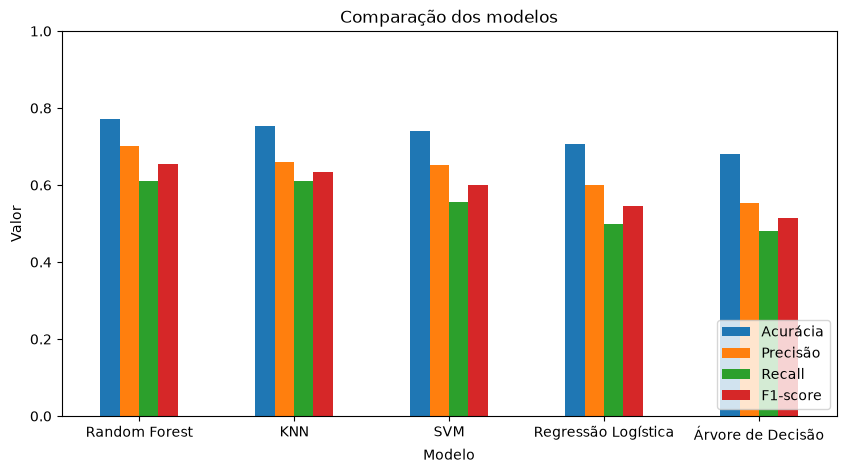

In [17]:
# comparando os modelos em grafico
tabela.set_index('Modelo').plot(kind='bar', figsize=(10, 5))
plt.title('Comparação dos modelos')
plt.ylabel('Valor')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

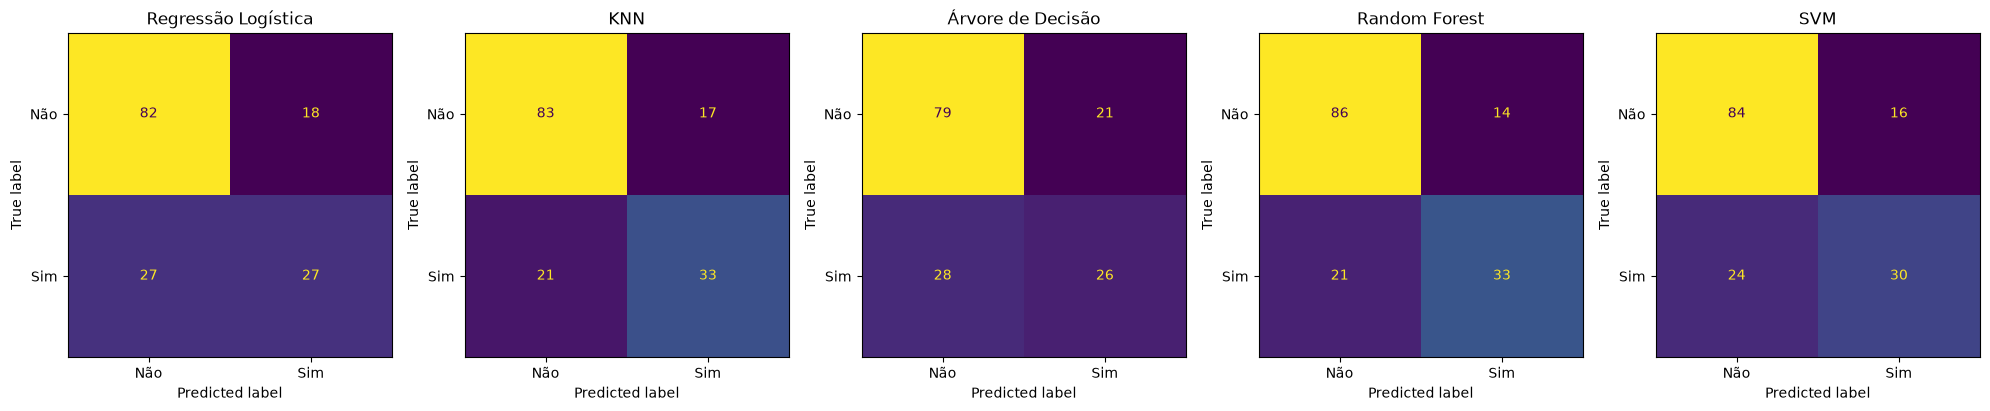

In [18]:
# matriz de confusao de cada modelo
fig, eixos = plt.subplots(1, 5, figsize=(20, 4))
for eixo, (nome, y_prev) in zip(eixos, previsoes.items()):
    matriz = confusion_matrix(y_teste, y_prev)
    ConfusionMatrixDisplay(matriz, display_labels=['Não', 'Sim']).plot(ax=eixo, colorbar=False)
    eixo.set_title(nome)
plt.tight_layout()
plt.show()

In [19]:
# relatorio completo do melhor modelo
melhor_nome = tabela.iloc[0]['Modelo']
print('Melhor modelo pelo F1-score:', melhor_nome)
print()
print(classification_report(y_teste, previsoes[melhor_nome], target_names=['Não tem', 'Tem diabetes']))

Melhor modelo pelo F1-score: Random Forest

              precision    recall  f1-score   support

     Não tem       0.80      0.86      0.83       100
Tem diabetes       0.70      0.61      0.65        54

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg       0.77      0.77      0.77       154



**Interpretação dos resultados:**

- O **Random Forest** teve o melhor desempenho geral: 77,3% de acurácia e F1-score de 0,653. O KNN ficou logo atrás (75,3% de acurácia).
- A **Árvore de Decisão** sozinha foi o pior modelo (68,2%). Sem limite de profundidade ela decora os dados de treino (overfitting) e erra mais nos dados novos. O Random Forest resolve parte disso juntando várias árvores.
- Pela matriz de confusão do Random Forest, das 54 pacientes com diabetes no teste, 33 foram identificadas e 21 não (recall de 0,61). Ou seja, o modelo ainda deixa passar cerca de 4 em cada 10 casos positivos, o que é um ponto fraco para um problema de saúde.
- Das 100 pacientes sem diabetes, 86 foram classificadas corretamente, então o modelo acerta mais a classe negativa, o que é esperado já que ela é a maioria na base.